<style>
.jp-Notebook{background:#f5f7fa!important;padding:28px 20px!important}.jp-Cell{margin-bottom:20px!important}
.jp-MarkdownCell .jp-InputPrompt{display:none!important}.jp-MarkdownOutput{padding:0!important}
.jp-CodeCell .jp-InputArea{border:1px solid #dce3ec!important;border-radius:10px!important;background:#f8fafc!important;padding:14px 8px!important}
.jp-CodeCell .cm-content,.highlight pre{font-family:'SFMono-Regular',Consolas,monospace!important;font-size:14px!important;line-height:1.65!important}
.jp-OutputArea-output{padding:16px 12px!important}.jp-OutputArea-output pre{font-size:13px!important;line-height:1.65!important}
.jp-RenderedHTMLCommon table.dataframe{font-size:14px!important;border-collapse:collapse!important;line-height:1.6!important}
.jp-RenderedHTMLCommon table.dataframe th{background:#edf3f8!important;padding:11px 14px!important}
.jp-RenderedHTMLCommon table.dataframe td{padding:10px 14px!important;border-bottom:1px solid #e3eaf2!important}
.jp-RenderedHTMLCommon table.dataframe tbody tr:nth-child(even){background:#f8fafc!important}
.jp-OutputArea-output img{display:block;margin:18px auto!important;max-width:100%!important}
@media(max-width:700px){.pads-reading{padding:22px 18px!important}.jp-Notebook{padding:12px 4px!important}}
</style>
<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h1 style="font-size:35px;line-height:1.25;letter-spacing:-.02em;color:#152b46;margin:10px 0 22px;">UWave gesture recognition</h1>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Four independent experiments follow the same reading structure as PADS: <strong style="color:#203b58;font-weight:650;">fully connected → RNN → LSTM → GRU</strong>. Each has its own network definition, dimensions, optimizer, explicit training loop, selected checkpoint and result plots.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Eight gesture labels are predicted from three acceleration channels. The supplied archive test set remains separate from training and validation.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Only the fully connected network interpolates recordings to a fixed length. Recurrent networks accept a padded batch and a vector of true lengths; true lengths identify the <strong style="color:#203b58;font-weight:650;">last valid hidden state</strong>, which supplies the classification features.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Use <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">environment.yml</code>, select Python (swipe-lecture), and run the cells in order. The first code cell downloads and verifies the source archive. All models run on CPU.</p>
</div>

<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Download-the-original-archive" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 01</span>Download the original archive</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The archive is stored locally and reused. SHA-256 verification detects a changed or corrupted download. Files are read directly from the ZIP without extracting paths.</p>
</div>

In [ ]:
from pathlib import Path
import urllib.request
import hashlib
import zipfile

DATA = Path("data/new_experiments")
DATA.mkdir(parents=True, exist_ok=True)
ARCHIVE = DATA / "uwave.zip"
URL = "https://www.timeseriesclassification.com/aeon-toolkit/UWaveGestureLibraryAll.zip"
EXPECTED_SHA256 = "fedcbb271e7149bd07fb564b66d2d62c98acbb6eb7857ba8267d95da12ca5f2a"
if not ARCHIVE.exists():
    temporary = ARCHIVE.with_suffix(".download")
    urllib.request.urlretrieve(URL, temporary)
    assert (
        hashlib.sha256(temporary.read_bytes()).hexdigest() == EXPECTED_SHA256
    ), "Archive changed; inspect the source before accepting it."
    temporary.replace(ARCHIVE)
assert hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_SHA256
with zipfile.ZipFile(ARCHIVE) as archive:
    assert archive.testzip() is None
print("Local archive:", ARCHIVE.resolve())
print("Downloaded size:", round(ARCHIVE.stat().st_size / 1024**2, 2), "MiB")


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Runtime-and-reproducibility" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 02</span>Runtime and reproducibility</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The seed is 42 and computation uses four CPU threads. An environment supplies Python and packages; selecting its registered kernel makes this notebook use that interpreter.</p>
<div class="highlight"><pre style="background:#f3f6fa;border:1px solid #e0e7ef;border-radius:8px;padding:18px 20px;margin:20px 0;font-size:14px;line-height:1.65;overflow-x:auto;"><span></span>conda<span class="w"> </span>env<span class="w"> </span>create<span class="w"> </span>-f<span class="w"> </span>environment.yml
conda<span class="w"> </span>activate<span class="w"> </span>swipe-lecture
python<span class="w"> </span>-m<span class="w"> </span>ipykernel<span class="w"> </span>install<span class="w"> </span>--user<span class="w"> </span>--name<span class="w"> </span>swipe-lecture<span class="w"> </span>--display-name<span class="w"> </span><span class="s2">"Python (swipe-lecture)"</span>
jupyter<span class="w"> </span>lab
</pre></div>
</div>

In [ ]:
import io
import json
import time
import copy
import random
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 13,
        "axes.titlesize": 17,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
display(
    HTML(
        "<style>.jp-RenderedHTMLCommon p{line-height:1.8;margin-bottom:24px}"
        ".jp-CodeCell .cm-content,.highlight pre{font-size:14px;line-height:1.6}</style>"
    )
)
print("Python / PyTorch:", torch.__version__, "| device:", DEVICE)

RESULTS = Path("results_uwave")
RESULTS.mkdir(exist_ok=True)

display(
    HTML(
        "<style>\n.jp-Notebook{background:#f5f7fa!important;padding:28px 20px!important}.jp-Cell{margin-bottom:20px!important}\n.jp-MarkdownCell .jp-InputPrompt{display:none!important}.jp-MarkdownOutput{padding:0!important}\n.jp-CodeCell .jp-InputArea{border:1px solid #dce3ec!important;border-radius:10px!important;background:#f8fafc!important;padding:14px 8px!important}\n.jp-CodeCell .cm-content,.highlight pre{font-family:'SFMono-Regular',Consolas,monospace!important;font-size:14px!important;line-height:1.65!important}\n.jp-OutputArea-output{padding:16px 12px!important}.jp-OutputArea-output pre{font-size:13px!important;line-height:1.65!important}\n.jp-RenderedHTMLCommon table.dataframe{font-size:14px!important;border-collapse:collapse!important;line-height:1.6!important}\n.jp-RenderedHTMLCommon table.dataframe th{background:#edf3f8!important;padding:11px 14px!important}\n.jp-RenderedHTMLCommon table.dataframe td{padding:10px 14px!important;border-bottom:1px solid #e3eaf2!important}\n.jp-RenderedHTMLCommon table.dataframe tbody tr:nth-child(even){background:#f8fafc!important}\n.jp-OutputArea-output img{display:block;margin:18px auto!important;max-width:100%!important}\n@media(max-width:700px){.pads-reading{padding:22px 18px!important}.jp-Notebook{padding:12px 4px!important}}\n</style>"
    )
)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Audit-participants,-sequences-and-labels" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 03</span>Audit participants, sequences and labels</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The UCR archive supplies 896 training recordings and 3,582 test recordings. Each contains 315 ordered samples for each of three acceleration axes. The axes are reconstructed into a 315 × 3 matrix. These are accelerations, not position coordinates. Participant identifiers and original timestamps are absent, so participant separation and the physical sampling rate cannot be verified from this archive.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;"><a href="https://www.timeseriesclassification.com/description.php?Dataset=UWaveGestureLibraryAll" style="color:#147f86;text-underline-offset:3px;">UCR dataset description</a></p>
</div>

In [ ]:
def load_uwave(partition):
    with zipfile.ZipFile(ARCHIVE) as archive:
        name = f"UWaveGestureLibraryAll_{partition}.txt"
        table = np.loadtxt(io.BytesIO(archive.read(name)))
    assert table.shape[1] == 946
    labels = table[:, 0].astype(np.int64) - 1
    sequences = table[:, 1:].reshape(-1, 3, 315).transpose(0, 2, 1)
    assert np.isfinite(sequences).all()
    assert set(labels) == set(range(8))
    return sequences.astype(np.float32), labels


X_archive_train, y_archive_train = load_uwave("TRAIN")
X_archive_test, y_archive_test = load_uwave("TEST")
CLASS_NAMES = [
    "Down-left",
    "Inverted U",
    "Right",
    "Left",
    "Up",
    "Down",
    "CCW circle",
    "CW circle",
]
CHANNEL_NAMES = ["Acceleration X", "Acceleration Y", "Acceleration Z"]
print("Archive training:", X_archive_train.shape)
print("Archive testing:", X_archive_test.shape)
display(pd.DataFrame(X_archive_train[0][:8], columns=CHANNEL_NAMES))
print("First recording label:", CLASS_NAMES[y_archive_train[0]])


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Class-distribution-and-actual-examples" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 04</span>Class distribution and actual examples</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The counts and percentages below describe the original selected data. Examples are chosen by class, without looking at model performance. Acceleration traces show ordered motion measurements; they are not spatial paths.</p>
</div>

In [ ]:
distribution = pd.DataFrame(
    {
        "class": CLASS_NAMES,
        "train_count": np.bincount(y_archive_train, minlength=8),
        "test_count": np.bincount(y_archive_test, minlength=8),
    }
)
distribution["train_percent"] = 100 * distribution.train_count / len(y_archive_train)
distribution["test_percent"] = 100 * distribution.test_count / len(y_archive_test)
display(distribution.round(2))
distribution.to_csv(RESULTS / "class_distribution.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, part in zip(axes, ["train", "test"]):
    bars = ax.barh(CLASS_NAMES, distribution[f"{part}_count"], color="#218B91")
    for bar, count, pct in zip(
        bars, distribution[f"{part}_count"], distribution[f"{part}_percent"]
    ):
        ax.text(
            count + 2,
            bar.get_y() + bar.get_height() / 2,
            f"{count} · {pct:.1f}%",
            va="center",
        )
    ax.set_xlim(0, distribution[f"{part}_count"].max() * 1.4)
    ax.set_title(f"Archive {part} recordings")
    ax.set_xlabel("Recordings")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(4, 2, figsize=(15, 13))
for label, ax in enumerate(axes.flat):
    sequence = X_archive_train[np.flatnonzero(y_archive_train == label)[0]]
    ax.plot(sequence)
    ax.set_title(CLASS_NAMES[label])
    ax.set_xlabel("Sample index")
    ax.set_ylabel("Archive acceleration value")
axes.flat[0].legend(CHANNEL_NAMES)
plt.tight_layout(h_pad=2.0)
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Split-first,-normalize-using-training-data-only" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 05</span>Split first, normalize using training data only</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Only the 896 archive training examples are split 80%/20% into training and validation. The archive test set is preserved. Recurrent models receive all 315 supplied steps; the benchmark has already fixed the sequence length, so natural length variation cannot be recovered from this archive. The recurrent implementation supports variable lengths and imposes no interpolation or global length requirement.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Normalization means and standard deviations are fitted on training measurements only. The same channel scaler is applied to validation and any held-out test sequences. FC interpolation happens afterward; recurrent sequences retain their lengths.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$\tilde x_{t,c}=\frac{x_{t,c}-\mu_c^{train}}{\max(\sigma_c^{train},10^{-6})}.$$</p>
</div>

In [ ]:
train_idx, val_idx = train_test_split(
    np.arange(len(X_archive_train)),
    test_size=0.2,
    stratify=y_archive_train,
    random_state=SEED,
)
train_sequences = [s for s in X_archive_train[train_idx]]
val_sequences = [s for s in X_archive_train[val_idx]]
evaluation_sequences = [s for s in X_archive_test]
y_train = y_archive_train[train_idx]
y_val = y_archive_train[val_idx]
y_evaluation = y_archive_test
manifest = pd.DataFrame(
    {"archive_train_row": np.arange(896), "class_id": y_archive_train, "split": "train"}
)
manifest.loc[val_idx, "split"] = "validation"


In [ ]:
assert not set(train_idx) & set(val_idx)
manifest.to_csv(RESULTS / "split_manifest.csv", index=False)
joined = np.concatenate(train_sequences, axis=0)
mean = joined.mean(0, keepdims=True)
std = np.maximum(joined.std(0, keepdims=True), 1e-6)
train_sequences = [((s - mean) / std).astype(np.float32) for s in train_sequences]
val_sequences = [((s - mean) / std).astype(np.float32) for s in val_sequences]
evaluation_sequences = [
    ((s - mean) / std).astype(np.float32) for s in evaluation_sequences
]
np.savez(RESULTS / "scaler.npz", mean=mean, std=std)
print("Training recordings:", len(train_sequences), "| validation:", len(val_sequences))
print("Evaluation recordings:", len(evaluation_sequences))
print(
    "Recurrent length range:",
    min(map(len, train_sequences)),
    max(map(len, train_sequences)),
)
display(manifest.groupby("split").size().rename("recordings").to_frame())
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist([len(s) for s in train_sequences], bins=20, color="#19878c")
ax.set_xlabel("Real steps per recording")
ax.set_title("Sequence lengths retained by recurrent models")
plt.tight_layout()
plt.show()


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Batching-and-result-displays" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 06</span>Batching and result displays</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">A batch is temporarily padded to its longest member. The true-length vector identifies which points are real. The output is always one label per recording. UWave packs the batch to ignore padding. For the spiral CPU implementation, the one-direction layer runs on the padded batch, then selects the output at <code style="font-family:'SFMono-Regular',Consolas,monospace;font-size:.88em;background:#edf3f8;border-radius:4px;padding:2px 5px;color:#29465f;">length - 1</code> for each recording. Later padded points cannot influence that earlier output. In both cases every real point is retained. The following helper only prepares data; it does not choose or train a model.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Accuracy counts correct predictions; balanced accuracy averages recall across classes; macro F1 gives every class equal weight. The shared display function calculates scores and draws plots. Each architecture below has its own training code.</p>
</div>

In [ ]:
class RecordingDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return torch.from_numpy(self.sequences[i]), int(self.labels[i])


def packed_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences], dtype=torch.long)
    return pad_sequence(sequences, batch_first=True), lengths, torch.tensor(labels)


comparison_rows = []


def display_results(name, history, probabilities, seconds, best_epoch):
    history = pd.DataFrame(history)
    predicted = probabilities.argmax(1)
    row = {
        "model": name,
        "evaluation": EVALUATION,
        "recordings": len(y_evaluation),
        "epochs": len(history),
        "best_epoch": best_epoch,
        "training_seconds": seconds,
        "accuracy": accuracy_score(y_evaluation, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_evaluation, predicted),
        "macro_F1": f1_score(y_evaluation, predicted, average="macro", zero_division=0),
    }
    comparison_rows.append(row)
    display(pd.DataFrame([row]).round(4))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    history.plot(
        x="epoch",
        y=["train_loss", "validation_loss"],
        ax=axes[0],
        title="Weighted cross-entropy",
    )
    history.plot(
        x="epoch", y="validation_accuracy", ax=axes[1], title="Validation accuracy"
    )
    history.plot(
        x="epoch", y="validation_macro_F1", ax=axes[2], title="Validation macro F1"
    )
    axes[1].set_ylim(0, 1)
    axes[2].set_ylim(0, 1)
    fig.suptitle(name, fontsize=20)
    plt.tight_layout()
    plt.show()
    ConfusionMatrixDisplay.from_predictions(
        y_evaluation,
        predicted,
        labels=np.arange(len(CLASS_NAMES)),
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45 if len(CLASS_NAMES) > 2 else 0,
    )
    plt.title(f"{name} · {EVALUATION}")
    plt.tight_layout()
    plt.show()
    print(
        classification_report(
            y_evaluation,
            predicted,
            labels=np.arange(len(CLASS_NAMES)),
            target_names=CLASS_NAMES,
            zero_division=0,
        )
    )
    predictions = pd.DataFrame({"true": y_evaluation, "predicted": predicted})
    for i, label in enumerate(CLASS_NAMES):
        predictions[label + " probability"] = probabilities[:, i]
    predictions.to_csv(RESULTS / f"{name}_{EVALUATION}_predictions.csv", index=False)
    history.to_csv(RESULTS / f"{name}_history.csv", index=False)
    pd.DataFrame(comparison_rows).to_csv(RESULTS / "comparison.csv", index=False)
    display(predictions.groupby("true").head(2).round(3))


EVALUATION = "test"


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="FC-%C2%B7-independent-experiment" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 07</span>FC · independent experiment</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">FC alone interpolates each scaled recording to 128 steps × 3 channels, then flattens to 384 features. Hidden layers contain 128 and 64 neurons. Interpolation changes temporal resolution and can remove fine detail.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$a_1=\mathrm{ReLU}(W_1v+b_1),\quad a_2=\mathrm{ReLU}(W_2a_1+b_2),\quad z=W_3a_2+b_3.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Dropout 0.15 regularizes hidden features. The final linear layer has 8 neurons. Cross-entropy receives logits directly; softmax is used to display probabilities. Sigmoid gates range from zero to one; $\odot$ denotes component-wise multiplication.</p>
</div>

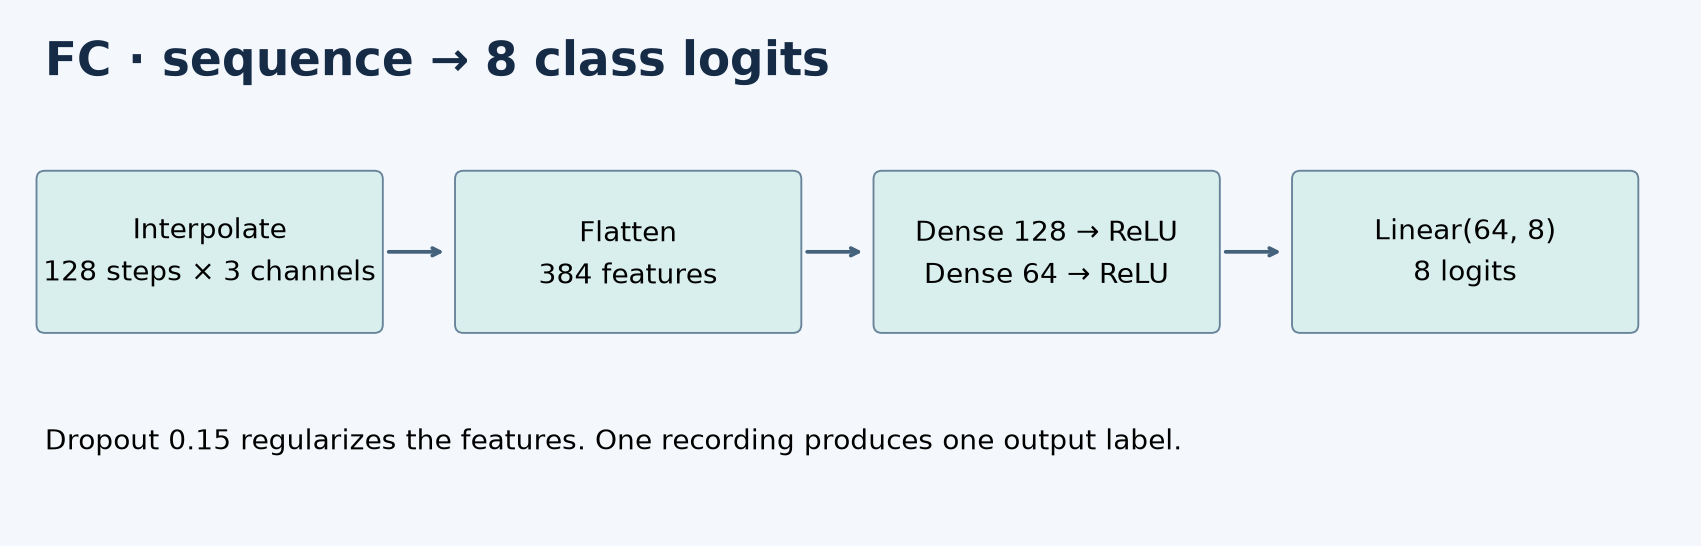

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">FC: input representation, hidden dimensions and class outputs</div>

In [ ]:
FC_STEPS = 128


def interpolate_fc(sequences):
    output = []
    for s in sequences:
        old = np.linspace(0, 1, len(s))
        new = np.linspace(0, 1, FC_STEPS)
        output.append(np.column_stack([np.interp(new, old, s[:, c]) for c in range(3)]))
    return np.stack(output).astype(np.float32)


fc_train_x = interpolate_fc(train_sequences)
fc_val_x = interpolate_fc(val_sequences)
fc_evaluation_x = interpolate_fc(evaluation_sequences)


class FCNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden1 = nn.Linear(384, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(0.15)
        self.output = nn.Linear(64, 8)

    def forward(self, x):
        x = self.flatten(x)
        x = self.dropout(self.activation(self.hidden1(x)))
        x = self.dropout(self.activation(self.hidden2(x)))
        return self.output(x)


torch.manual_seed(SEED)
fc_model = FCNetwork().to(DEVICE)
fc_train_loader = DataLoader(
    TensorDataset(torch.from_numpy(fc_train_x), torch.from_numpy(y_train)),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
fc_val_loader = DataLoader(
    TensorDataset(torch.from_numpy(fc_val_x), torch.from_numpy(y_val)), batch_size=64
)
fc_evaluation_loader = DataLoader(
    TensorDataset(torch.from_numpy(fc_evaluation_x), torch.from_numpy(y_evaluation)),
    batch_size=64,
)
print(fc_model)
display(
    pd.DataFrame(
        [
            ["Input", 3, "B × 128 × 3"],
            ["Flatten", 384, "B × 384"],
            ["Dense + ReLU", 128, "B × 128"],
            ["Dense + ReLU", 64, "B × 64"],
            ["Logits", 8, "B × 8"],
        ],
        columns=["layer", "neurons_or_channels", "output_shape"],
    )
)
print(
    "Input:",
    fc_train_x.shape,
    "| trainable parameters:",
    sum(p.numel() for p in fc_model.parameters()),
)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="FC-training-and-test-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">FC training and test results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">This model has its own optimizer, weighted cross-entropy and explicit training loop. Adam uses learning rate 0.001, weight decay 0.0001 and gradient clipping at 1.0. Maximum epochs are 40, with patience 8 after at least ten epochs.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The highest validation <strong style="color:#203b58;font-weight:650;">macro F1</strong> selects the checkpoint; lower validation loss breaks exact ties. The archive test data are evaluated only after restoring that checkpoint.</p>
</div>

In [ ]:
fc_counts = np.bincount(y_train, minlength=8)
fc_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(len(y_train) / (8 * fc_counts), dtype=torch.float32).to(DEVICE)
)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001, weight_decay=0.0001)
fc_history = []
fc_best_score = -1.0
fc_best_loss = float("inf")
fc_stale = 0
fc_started = time.perf_counter()
for fc_epoch in range(1, 41):
    fc_model.train()
    fc_total = 0.0
    for fc_x, fc_y in fc_train_loader:
        fc_optimizer.zero_grad()
        fc_logits = fc_model(fc_x.to(DEVICE))
        fc_loss = fc_criterion(fc_logits, fc_y.to(DEVICE))
        fc_loss.backward()
        nn.utils.clip_grad_norm_(fc_model.parameters(), 1.0)
        fc_optimizer.step()
        fc_total += fc_loss.item() * len(fc_y)
    fc_model.eval()
    fc_batches = []
    with torch.no_grad():
        for fc_x, fc_y in fc_val_loader:
            fc_batches.append(fc_model(fc_x.to(DEVICE)).cpu())
    fc_val_logits = torch.cat(fc_batches)
    fc_val_loss = fc_criterion(
        fc_val_logits.to(DEVICE), torch.from_numpy(y_val).to(DEVICE)
    ).item()
    fc_accuracy = accuracy_score(y_val, fc_val_logits.argmax(1).numpy())
    fc_f1 = f1_score(
        y_val, fc_val_logits.argmax(1).numpy(), average="macro", zero_division=0
    )
    fc_score = fc_f1
    fc_history.append(
        {
            "epoch": fc_epoch,
            "train_loss": fc_total / len(y_train),
            "validation_loss": fc_val_loss,
            "validation_accuracy": fc_accuracy,
            "validation_macro_F1": fc_f1,
        }
    )
    if fc_score > fc_best_score + 1e-6 or (
        abs(fc_score - fc_best_score) <= 1e-6 and fc_val_loss < fc_best_loss
    ):
        fc_best_score = fc_score
        fc_best_loss = fc_val_loss
        fc_stale = 0
        fc_best_weights = copy.deepcopy(fc_model.state_dict())
        fc_best_epoch = fc_epoch
    else:
        fc_stale += 1
    pd.DataFrame(fc_history).to_csv(RESULTS / "FC_history.csv", index=False)
    if fc_epoch == 1 or fc_epoch % 5 == 0:
        print(
            "FC epoch",
            fc_epoch,
            "| validation accuracy",
            round(fc_accuracy, 3),
            flush=True,
        )
    if fc_stale >= 8 and fc_epoch >= 10:
        break
fc_seconds = time.perf_counter() - fc_started
fc_model.load_state_dict(fc_best_weights)
fc_model.eval()
fc_batches = []
with torch.no_grad():
    for fc_x, fc_y in fc_evaluation_loader:
        fc_batches.append(fc_model(fc_x.to(DEVICE)).cpu())
fc_probabilities = torch.cat(fc_batches).softmax(1).numpy()
torch.save(
    {
        "weights": fc_best_weights,
        "architecture": "FCNetwork",
        "channels": CHANNEL_NAMES,
        "classes": CLASS_NAMES,
        "mean": mean.tolist(),
        "std": std.tolist(),
        "FC_steps": 128,
        "hidden_size": 64,
        "best_epoch": fc_best_epoch,
    },
    RESULTS / "FC_checkpoint.pt",
)
display_results("FC", fc_history, fc_probabilities, fc_seconds, fc_best_epoch)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="RNN-%C2%B7-independent-experiment" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 08</span>RNN · independent experiment</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">One RNN layer has 64 hidden components. Each point contains 3 channels. Every valid time step is retained; the last valid hidden state has shape B × 64. No temporal averaging or concatenation is used. Initial states are zero for every recording, and state is never carried between recordings. Repeated updates can lose early information or produce shrinking or growing gradients. Clipping limits large gradients but does not guarantee long-range memory. Input weights have shape $64\times3$ and recurrent weights have shape $64\times64$.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh}).$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Dropout 0.15 regularizes hidden features. The final linear layer has 8 neurons. Cross-entropy receives logits directly; softmax is used to display probabilities. Sigmoid gates range from zero to one; $\odot$ denotes component-wise multiplication.</p>
</div>

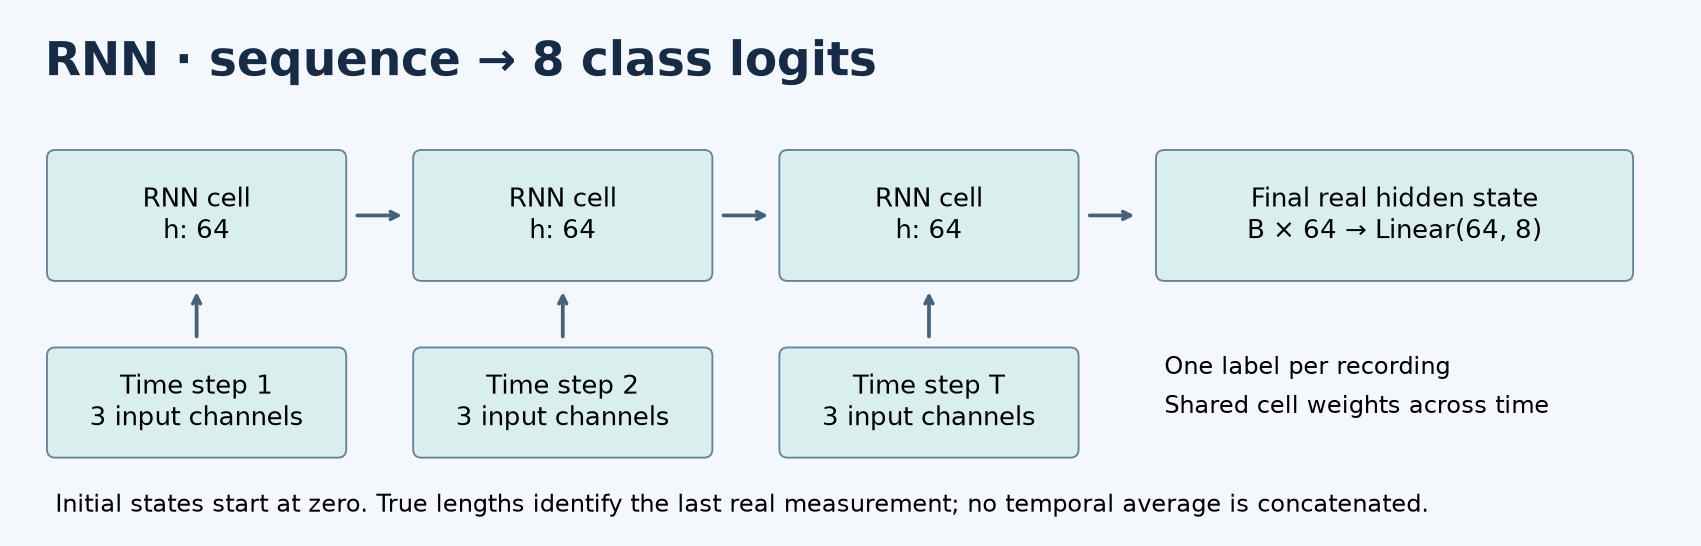

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">RNN: input representation, hidden dimensions and class outputs</div>

In [ ]:
class RNNNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.RNN(
            input_size=3, hidden_size=64, num_layers=1, batch_first=True
        )
        self.dropout = nn.Dropout(0.15)
        self.output = nn.Linear(64, 8)

    def forward(self, padded, lengths):
        packed = pack_padded_sequence(
            padded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.recurrent(packed)
        return self.output(self.dropout(hidden[-1]))


torch.manual_seed(SEED)
rnn_model = RNNNetwork().to(DEVICE)
rnn_train_loader = DataLoader(
    RecordingDataset(train_sequences, y_train),
    batch_size=32,
    shuffle=True,
    collate_fn=packed_batch,
    generator=torch.Generator().manual_seed(SEED),
)
rnn_val_loader = DataLoader(
    RecordingDataset(val_sequences, y_val), batch_size=64, collate_fn=packed_batch
)
rnn_evaluation_loader = DataLoader(
    RecordingDataset(evaluation_sequences, y_evaluation),
    batch_size=64,
    collate_fn=packed_batch,
)
print(rnn_model)
display(
    pd.DataFrame(
        [
            ["Input", 3, "B × Lmax × 3 + lengths"],
            ["One RNN layer", 64, "1 × B × 64"],
            ["Final hidden", 64, "B × 64"],
            ["Logits", 8, "B × 8"],
        ],
        columns=["layer", "neurons_or_channels", "output_shape"],
    )
)
print("Trainable parameters:", sum(p.numel() for p in rnn_model.parameters()))
rnn_sample, rnn_lengths, _ = next(iter(rnn_val_loader))
rnn_model.eval()
with torch.no_grad():
    rnn_a = rnn_model(rnn_sample, rnn_lengths)
    rnn_b = rnn_model(
        torch.cat([rnn_sample, torch.ones(len(rnn_sample), 7, 3)], dim=1), rnn_lengths
    )
assert torch.allclose(rnn_a, rnn_b, atol=1e-6)
print(
    "Batch:",
    tuple(rnn_sample.shape),
    "| true lengths:",
    rnn_lengths[:8].tolist(),
    "| logits:",
    tuple(rnn_a.shape),
)
print("Verified: extra padding does not affect predictions.")


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="RNN-training-and-test-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">RNN training and test results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">This model has its own optimizer, weighted cross-entropy and explicit training loop. Adam uses learning rate 0.001, weight decay 0.0001 and gradient clipping at 1.0. Maximum epochs are 40, with patience 8 after at least ten epochs.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The highest validation <strong style="color:#203b58;font-weight:650;">macro F1</strong> selects the checkpoint; lower validation loss breaks exact ties. The archive test data are evaluated only after restoring that checkpoint.</p>
</div>

In [ ]:
rnn_counts = np.bincount(y_train, minlength=8)
rnn_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(len(y_train) / (8 * rnn_counts), dtype=torch.float32).to(DEVICE)
)
rnn_optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001, weight_decay=0.0001)
rnn_history = []
rnn_best_score = -1.0
rnn_best_loss = float("inf")
rnn_stale = 0
rnn_started = time.perf_counter()
for rnn_epoch in range(1, 41):
    rnn_model.train()
    rnn_total = 0.0
    for rnn_x, rnn_lengths, rnn_y in rnn_train_loader:
        rnn_optimizer.zero_grad()
        rnn_logits = rnn_model(rnn_x.to(DEVICE), rnn_lengths)
        rnn_loss = rnn_criterion(rnn_logits, rnn_y.to(DEVICE))
        rnn_loss.backward()
        nn.utils.clip_grad_norm_(rnn_model.parameters(), 1.0)
        rnn_optimizer.step()
        rnn_total += rnn_loss.item() * len(rnn_y)
    rnn_model.eval()
    rnn_batches = []
    with torch.no_grad():
        for rnn_x, rnn_lengths, rnn_y in rnn_val_loader:
            rnn_batches.append(rnn_model(rnn_x.to(DEVICE), rnn_lengths).cpu())
    rnn_val_logits = torch.cat(rnn_batches)
    rnn_val_loss = rnn_criterion(
        rnn_val_logits.to(DEVICE), torch.from_numpy(y_val).to(DEVICE)
    ).item()
    rnn_accuracy = accuracy_score(y_val, rnn_val_logits.argmax(1).numpy())
    rnn_f1 = f1_score(
        y_val, rnn_val_logits.argmax(1).numpy(), average="macro", zero_division=0
    )
    rnn_score = rnn_f1
    rnn_history.append(
        {
            "epoch": rnn_epoch,
            "train_loss": rnn_total / len(y_train),
            "validation_loss": rnn_val_loss,
            "validation_accuracy": rnn_accuracy,
            "validation_macro_F1": rnn_f1,
        }
    )
    if rnn_score > rnn_best_score + 1e-6 or (
        abs(rnn_score - rnn_best_score) <= 1e-6 and rnn_val_loss < rnn_best_loss
    ):
        rnn_best_score = rnn_score
        rnn_best_loss = rnn_val_loss
        rnn_stale = 0
        rnn_best_weights = copy.deepcopy(rnn_model.state_dict())
        rnn_best_epoch = rnn_epoch
    else:
        rnn_stale += 1
    pd.DataFrame(rnn_history).to_csv(RESULTS / "RNN_history.csv", index=False)
    if rnn_epoch == 1 or rnn_epoch % 5 == 0:
        print(
            "RNN epoch",
            rnn_epoch,
            "| validation accuracy",
            round(rnn_accuracy, 3),
            flush=True,
        )
    if rnn_stale >= 8 and rnn_epoch >= 10:
        break
rnn_seconds = time.perf_counter() - rnn_started
rnn_model.load_state_dict(rnn_best_weights)
rnn_model.eval()
rnn_batches = []
with torch.no_grad():
    for rnn_x, rnn_lengths, rnn_y in rnn_evaluation_loader:
        rnn_batches.append(rnn_model(rnn_x.to(DEVICE), rnn_lengths).cpu())
rnn_probabilities = torch.cat(rnn_batches).softmax(1).numpy()
torch.save(
    {
        "weights": rnn_best_weights,
        "architecture": "RNNNetwork",
        "channels": CHANNEL_NAMES,
        "classes": CLASS_NAMES,
        "mean": mean.tolist(),
        "std": std.tolist(),
        "FC_steps": None,
        "hidden_size": 64,
        "best_epoch": rnn_best_epoch,
    },
    RESULTS / "RNN_checkpoint.pt",
)
display_results("RNN", rnn_history, rnn_probabilities, rnn_seconds, rnn_best_epoch)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="LSTM-%C2%B7-independent-experiment" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 09</span>LSTM · independent experiment</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">One LSTM layer has 64 hidden components. Each point contains 3 channels. Every valid time step is retained; the last valid hidden state has shape B × 64. No temporal averaging or concatenation is used. Initial states are zero for every recording, and state is never carried between recordings. Four gates produce stacked input weights $256\times3$ and recurrent weights $256\times64$. The cell memory c and exposed hidden state h are separate 64-component vectors. Input, forget and output gates control memory; only final h feeds the classifier.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i),\quad f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)$$
$$g_t=\tanh(W_g x_t+U_g h_{t-1}+b_g),\quad o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\quad h_t=o_t\odot\tanh(c_t).$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Dropout 0.15 regularizes hidden features. The final linear layer has 8 neurons. Cross-entropy receives logits directly; softmax is used to display probabilities. Sigmoid gates range from zero to one; $\odot$ denotes component-wise multiplication.</p>
</div>

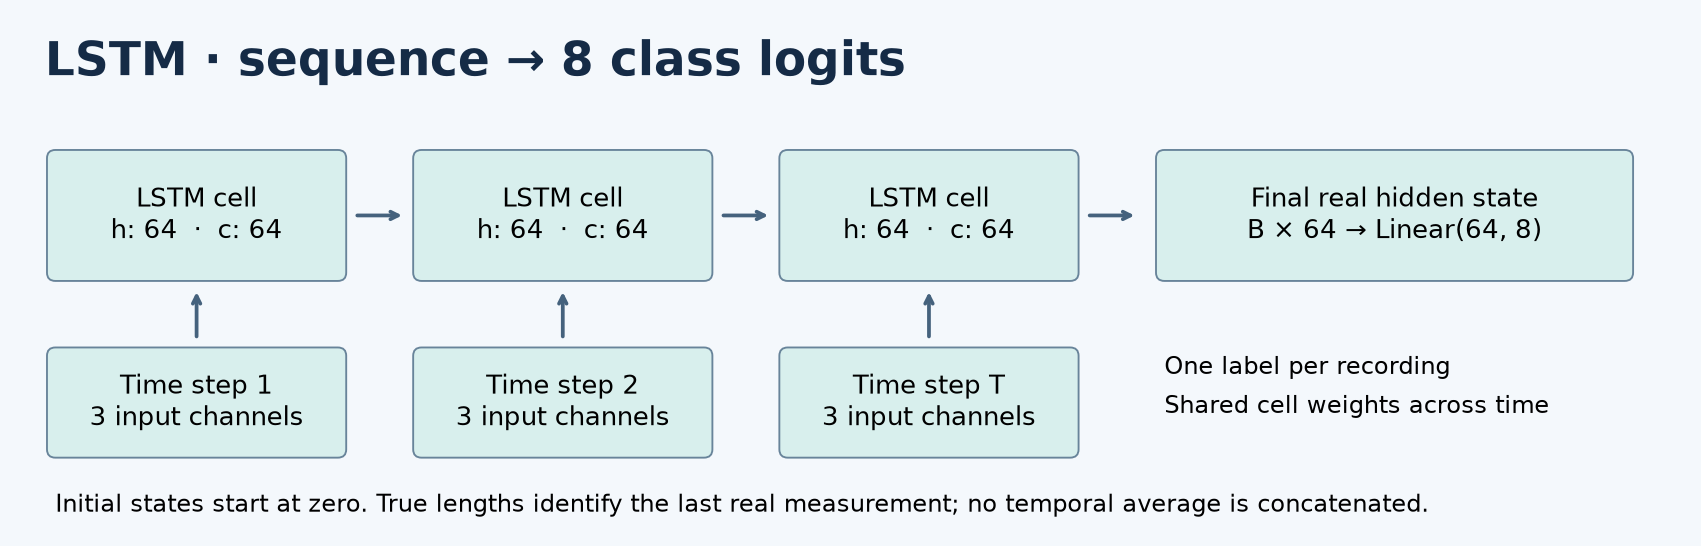

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">LSTM: input representation, hidden dimensions and class outputs</div>

In [ ]:
class LSTMNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=3, hidden_size=64, num_layers=1, batch_first=True
        )
        self.dropout = nn.Dropout(0.15)
        self.output = nn.Linear(64, 8)

    def forward(self, padded, lengths):
        packed = pack_padded_sequence(
            padded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, cell) = self.recurrent(packed)
        return self.output(self.dropout(hidden[-1]))


torch.manual_seed(SEED)
lstm_model = LSTMNetwork().to(DEVICE)
lstm_train_loader = DataLoader(
    RecordingDataset(train_sequences, y_train),
    batch_size=32,
    shuffle=True,
    collate_fn=packed_batch,
    generator=torch.Generator().manual_seed(SEED),
)
lstm_val_loader = DataLoader(
    RecordingDataset(val_sequences, y_val), batch_size=64, collate_fn=packed_batch
)
lstm_evaluation_loader = DataLoader(
    RecordingDataset(evaluation_sequences, y_evaluation),
    batch_size=64,
    collate_fn=packed_batch,
)
print(lstm_model)
display(
    pd.DataFrame(
        [
            ["Input", 3, "B × Lmax × 3 + lengths"],
            ["One LSTM layer", 64, "1 × B × 64"],
            ["Final hidden", 64, "B × 64"],
            ["Logits", 8, "B × 8"],
        ],
        columns=["layer", "neurons_or_channels", "output_shape"],
    )
)
print("Trainable parameters:", sum(p.numel() for p in lstm_model.parameters()))
lstm_sample, lstm_lengths, _ = next(iter(lstm_val_loader))
lstm_model.eval()
with torch.no_grad():
    lstm_a = lstm_model(lstm_sample, lstm_lengths)
    lstm_b = lstm_model(
        torch.cat([lstm_sample, torch.ones(len(lstm_sample), 7, 3)], dim=1),
        lstm_lengths,
    )
assert torch.allclose(lstm_a, lstm_b, atol=1e-6)
print(
    "Batch:",
    tuple(lstm_sample.shape),
    "| true lengths:",
    lstm_lengths[:8].tolist(),
    "| logits:",
    tuple(lstm_a.shape),
)
print("Verified: extra padding does not affect predictions.")


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="LSTM-training-and-test-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">LSTM training and test results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">This model has its own optimizer, weighted cross-entropy and explicit training loop. Adam uses learning rate 0.001, weight decay 0.0001 and gradient clipping at 1.0. Maximum epochs are 40, with patience 8 after at least ten epochs.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The highest validation <strong style="color:#203b58;font-weight:650;">macro F1</strong> selects the checkpoint; lower validation loss breaks exact ties. The archive test data are evaluated only after restoring that checkpoint.</p>
</div>

In [ ]:
lstm_counts = np.bincount(y_train, minlength=8)
lstm_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(len(y_train) / (8 * lstm_counts), dtype=torch.float32).to(
        DEVICE
    )
)
lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(), lr=0.001, weight_decay=0.0001
)
lstm_history = []
lstm_best_score = -1.0
lstm_best_loss = float("inf")
lstm_stale = 0
lstm_started = time.perf_counter()
for lstm_epoch in range(1, 41):
    lstm_model.train()
    lstm_total = 0.0
    for lstm_x, lstm_lengths, lstm_y in lstm_train_loader:
        lstm_optimizer.zero_grad()
        lstm_logits = lstm_model(lstm_x.to(DEVICE), lstm_lengths)
        lstm_loss = lstm_criterion(lstm_logits, lstm_y.to(DEVICE))
        lstm_loss.backward()
        nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        lstm_optimizer.step()
        lstm_total += lstm_loss.item() * len(lstm_y)
    lstm_model.eval()
    lstm_batches = []
    with torch.no_grad():
        for lstm_x, lstm_lengths, lstm_y in lstm_val_loader:
            lstm_batches.append(lstm_model(lstm_x.to(DEVICE), lstm_lengths).cpu())
    lstm_val_logits = torch.cat(lstm_batches)
    lstm_val_loss = lstm_criterion(
        lstm_val_logits.to(DEVICE), torch.from_numpy(y_val).to(DEVICE)
    ).item()
    lstm_accuracy = accuracy_score(y_val, lstm_val_logits.argmax(1).numpy())
    lstm_f1 = f1_score(
        y_val, lstm_val_logits.argmax(1).numpy(), average="macro", zero_division=0
    )
    lstm_score = lstm_f1
    lstm_history.append(
        {
            "epoch": lstm_epoch,
            "train_loss": lstm_total / len(y_train),
            "validation_loss": lstm_val_loss,
            "validation_accuracy": lstm_accuracy,
            "validation_macro_F1": lstm_f1,
        }
    )
    if lstm_score > lstm_best_score + 1e-6 or (
        abs(lstm_score - lstm_best_score) <= 1e-6 and lstm_val_loss < lstm_best_loss
    ):
        lstm_best_score = lstm_score
        lstm_best_loss = lstm_val_loss
        lstm_stale = 0
        lstm_best_weights = copy.deepcopy(lstm_model.state_dict())
        lstm_best_epoch = lstm_epoch
    else:
        lstm_stale += 1
    pd.DataFrame(lstm_history).to_csv(RESULTS / "LSTM_history.csv", index=False)
    if lstm_epoch == 1 or lstm_epoch % 5 == 0:
        print(
            "LSTM epoch",
            lstm_epoch,
            "| validation accuracy",
            round(lstm_accuracy, 3),
            flush=True,
        )
    if lstm_stale >= 8 and lstm_epoch >= 10:
        break
lstm_seconds = time.perf_counter() - lstm_started
lstm_model.load_state_dict(lstm_best_weights)
lstm_model.eval()
lstm_batches = []
with torch.no_grad():
    for lstm_x, lstm_lengths, lstm_y in lstm_evaluation_loader:
        lstm_batches.append(lstm_model(lstm_x.to(DEVICE), lstm_lengths).cpu())
lstm_probabilities = torch.cat(lstm_batches).softmax(1).numpy()
torch.save(
    {
        "weights": lstm_best_weights,
        "architecture": "LSTMNetwork",
        "channels": CHANNEL_NAMES,
        "classes": CLASS_NAMES,
        "mean": mean.tolist(),
        "std": std.tolist(),
        "FC_steps": None,
        "hidden_size": 64,
        "best_epoch": lstm_best_epoch,
    },
    RESULTS / "LSTM_checkpoint.pt",
)
display_results("LSTM", lstm_history, lstm_probabilities, lstm_seconds, lstm_best_epoch)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="GRU-%C2%B7-independent-experiment" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 10</span>GRU · independent experiment</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">One GRU layer has 64 hidden components. Each point contains 3 channels. Every valid time step is retained; the last valid hidden state has shape B × 64. No temporal averaging or concatenation is used. Initial states are zero for every recording, and state is never carried between recordings. Three gate computations produce stacked input weights $192\times3$ and recurrent weights $192\times64$. Reset and update gates control the candidate and retained hidden state; there is no separate cell-memory vector. These equations use PyTorch’s reset-gate placement.</p>
<p style="font-size:18px;line-height:1.8;padding:18px 20px;background:#f1f6fa;border:1px solid #e4ecf3;border-radius:8px;margin:20px 0;overflow-x:auto;text-align:center;">$$r_t=\sigma(W_{ir}x_t+b_{ir}+W_{hr}h_{t-1}+b_{hr})$$
$$z_t=\sigma(W_{iz}x_t+b_{iz}+W_{hz}h_{t-1}+b_{hz})$$
$$n_t=\tanh(W_{in}x_t+b_{in}+r_t\odot(W_{hn}h_{t-1}+b_{hn}))$$
$$h_t=(1-z_t)\odot n_t+z_t\odot h_{t-1}.$$</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">Dropout 0.15 regularizes hidden features. The final linear layer has 8 neurons. Cross-entropy receives logits directly; softmax is used to display probabilities. Sigmoid gates range from zero to one; $\odot$ denotes component-wise multiplication.</p>
</div>

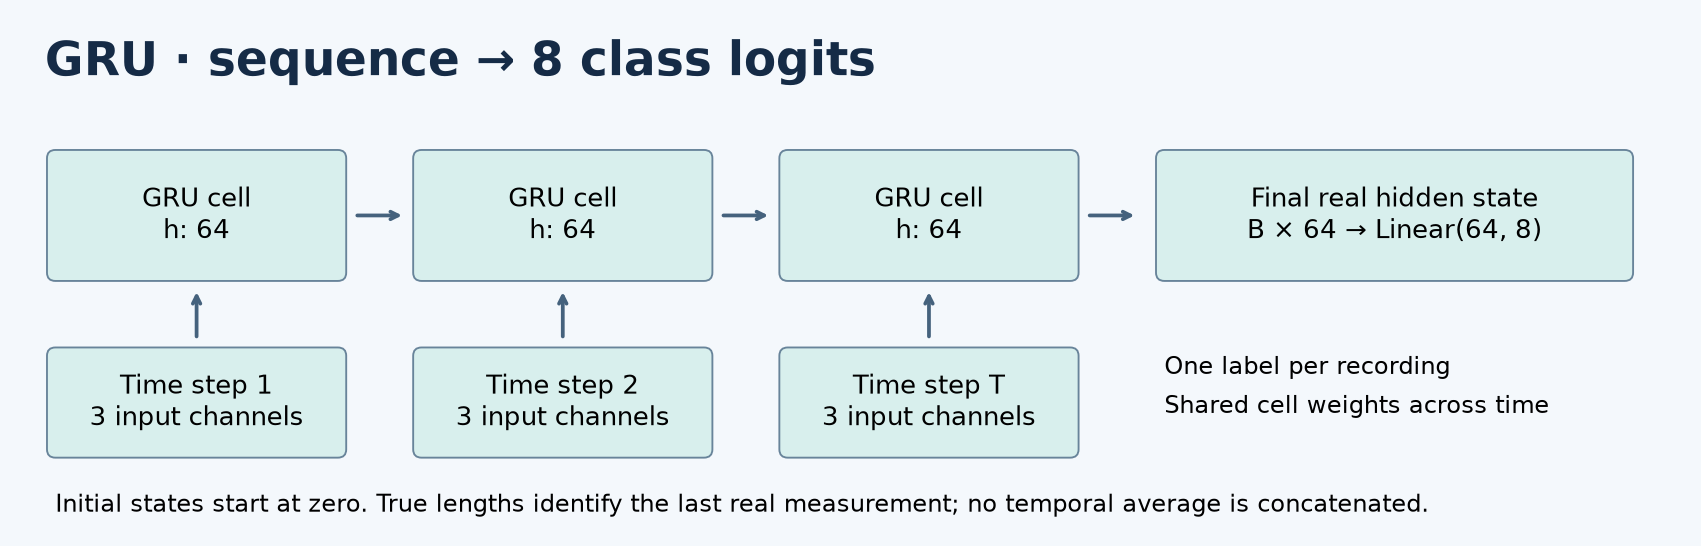

<div style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;font-size:13px;color:#64748b;text-align:center;margin:8px 0 22px">GRU: input representation, hidden dimensions and class outputs</div>

In [ ]:
class GRUNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.GRU(
            input_size=3, hidden_size=64, num_layers=1, batch_first=True
        )
        self.dropout = nn.Dropout(0.15)
        self.output = nn.Linear(64, 8)

    def forward(self, padded, lengths):
        packed = pack_padded_sequence(
            padded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.recurrent(packed)
        return self.output(self.dropout(hidden[-1]))


torch.manual_seed(SEED)
gru_model = GRUNetwork().to(DEVICE)
gru_train_loader = DataLoader(
    RecordingDataset(train_sequences, y_train),
    batch_size=32,
    shuffle=True,
    collate_fn=packed_batch,
    generator=torch.Generator().manual_seed(SEED),
)
gru_val_loader = DataLoader(
    RecordingDataset(val_sequences, y_val), batch_size=64, collate_fn=packed_batch
)
gru_evaluation_loader = DataLoader(
    RecordingDataset(evaluation_sequences, y_evaluation),
    batch_size=64,
    collate_fn=packed_batch,
)
print(gru_model)
display(
    pd.DataFrame(
        [
            ["Input", 3, "B × Lmax × 3 + lengths"],
            ["One GRU layer", 64, "1 × B × 64"],
            ["Final hidden", 64, "B × 64"],
            ["Logits", 8, "B × 8"],
        ],
        columns=["layer", "neurons_or_channels", "output_shape"],
    )
)
print("Trainable parameters:", sum(p.numel() for p in gru_model.parameters()))
gru_sample, gru_lengths, _ = next(iter(gru_val_loader))
gru_model.eval()
with torch.no_grad():
    gru_a = gru_model(gru_sample, gru_lengths)
    gru_b = gru_model(
        torch.cat([gru_sample, torch.ones(len(gru_sample), 7, 3)], dim=1), gru_lengths
    )
assert torch.allclose(gru_a, gru_b, atol=1e-6)
print(
    "Batch:",
    tuple(gru_sample.shape),
    "| true lengths:",
    gru_lengths[:8].tolist(),
    "| logits:",
    tuple(gru_a.shape),
)
print("Verified: extra padding does not affect predictions.")


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h3 id="GRU-training-and-test-results" style="font-size:21px;line-height:1.4;font-weight:650;color:#16858a;margin:0 0 18px;">GRU training and test results</h3><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">This model has its own optimizer, weighted cross-entropy and explicit training loop. Adam uses learning rate 0.001, weight decay 0.0001 and gradient clipping at 1.0. Maximum epochs are 40, with patience 8 after at least ten epochs.</p>
<p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The highest validation <strong style="color:#203b58;font-weight:650;">macro F1</strong> selects the checkpoint; lower validation loss breaks exact ties. The archive test data are evaluated only after restoring that checkpoint.</p>
</div>

In [ ]:
gru_counts = np.bincount(y_train, minlength=8)
gru_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(len(y_train) / (8 * gru_counts), dtype=torch.float32).to(DEVICE)
)
gru_optimizer = torch.optim.Adam(gru_model.parameters(), lr=0.001, weight_decay=0.0001)
gru_history = []
gru_best_score = -1.0
gru_best_loss = float("inf")
gru_stale = 0
gru_started = time.perf_counter()
for gru_epoch in range(1, 41):
    gru_model.train()
    gru_total = 0.0
    for gru_x, gru_lengths, gru_y in gru_train_loader:
        gru_optimizer.zero_grad()
        gru_logits = gru_model(gru_x.to(DEVICE), gru_lengths)
        gru_loss = gru_criterion(gru_logits, gru_y.to(DEVICE))
        gru_loss.backward()
        nn.utils.clip_grad_norm_(gru_model.parameters(), 1.0)
        gru_optimizer.step()
        gru_total += gru_loss.item() * len(gru_y)
    gru_model.eval()
    gru_batches = []
    with torch.no_grad():
        for gru_x, gru_lengths, gru_y in gru_val_loader:
            gru_batches.append(gru_model(gru_x.to(DEVICE), gru_lengths).cpu())
    gru_val_logits = torch.cat(gru_batches)
    gru_val_loss = gru_criterion(
        gru_val_logits.to(DEVICE), torch.from_numpy(y_val).to(DEVICE)
    ).item()
    gru_accuracy = accuracy_score(y_val, gru_val_logits.argmax(1).numpy())
    gru_f1 = f1_score(
        y_val, gru_val_logits.argmax(1).numpy(), average="macro", zero_division=0
    )
    gru_score = gru_f1
    gru_history.append(
        {
            "epoch": gru_epoch,
            "train_loss": gru_total / len(y_train),
            "validation_loss": gru_val_loss,
            "validation_accuracy": gru_accuracy,
            "validation_macro_F1": gru_f1,
        }
    )
    if gru_score > gru_best_score + 1e-6 or (
        abs(gru_score - gru_best_score) <= 1e-6 and gru_val_loss < gru_best_loss
    ):
        gru_best_score = gru_score
        gru_best_loss = gru_val_loss
        gru_stale = 0
        gru_best_weights = copy.deepcopy(gru_model.state_dict())
        gru_best_epoch = gru_epoch
    else:
        gru_stale += 1
    pd.DataFrame(gru_history).to_csv(RESULTS / "GRU_history.csv", index=False)
    if gru_epoch == 1 or gru_epoch % 5 == 0:
        print(
            "GRU epoch",
            gru_epoch,
            "| validation accuracy",
            round(gru_accuracy, 3),
            flush=True,
        )
    if gru_stale >= 8 and gru_epoch >= 10:
        break
gru_seconds = time.perf_counter() - gru_started
gru_model.load_state_dict(gru_best_weights)
gru_model.eval()
gru_batches = []
with torch.no_grad():
    for gru_x, gru_lengths, gru_y in gru_evaluation_loader:
        gru_batches.append(gru_model(gru_x.to(DEVICE), gru_lengths).cpu())
gru_probabilities = torch.cat(gru_batches).softmax(1).numpy()
torch.save(
    {
        "weights": gru_best_weights,
        "architecture": "GRUNetwork",
        "channels": CHANNEL_NAMES,
        "classes": CLASS_NAMES,
        "mean": mean.tolist(),
        "std": std.tolist(),
        "FC_steps": None,
        "hidden_size": 64,
        "best_epoch": gru_best_epoch,
    },
    RESULTS / "GRU_checkpoint.pt",
)
display_results("GRU", gru_history, gru_probabilities, gru_seconds, gru_best_epoch)


<div class="pads-reading" style="font-family:-apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif;max-width:960px;background:#fff;border:1px solid #e2e8f0;border-radius:12px;margin:12px auto 18px;padding:28px 32px;color:#36465a"><h2 id="Compare-the-measured-results" style="font-size:27px;line-height:1.3;font-weight:650;color:#152b46;margin:0 0 22px;padding-bottom:16px;border-bottom:1px solid #e5ebf2;"><span style="display:block;font-size:12px;letter-spacing:.14em;font-weight:700;color:#16858a;margin:0 0 10px;">SECTION 11</span>Compare the measured results</h2><p style="font-size:17px;line-height:1.75;margin:0 0 18px;color:#36465a;">The scores describe the archive test split. Participant identifiers are missing, so this is not a verified participant-disjoint benchmark. FC sees interpolated inputs while recurrent models retain all supplied points; the comparison measures complete pipelines rather than architecture alone.</p>
</div>

In [ ]:
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison.set_index("model")[["accuracy", "balanced_accuracy", "macro_F1"]].plot.bar(
    ax=axes[0]
)
axes[0].set_ylim(0, 1.05)
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=11
)
axes[0].set_title(f"{EVALUATION.capitalize()} scores")
axes[0].tick_params(axis="x", rotation=0)
axes[1].bar(comparison.model, comparison.training_seconds / 60, color="#19878c")
axes[1].set_ylabel("Minutes")
axes[1].set_title("Measured training and validation time")
plt.tight_layout()
plt.show()
print(
    "Total training and validation minutes:",
    round(comparison.training_seconds.sum() / 60, 2),
)
